# COURSE NAME: DATA MINING, MODELING AND ANALYTICS

# Assignment 1
# BY NANFUKA FATUMA
# B36106

# Project 2: Concrete Compressive Strength
**Task:** Predict compressive strength (MPa) from mixture composition and curing age.

The analysis follows the three numbered questions in Part A. I compare a mean baseline, a regularised linear model, and two nonlinear methods, then examine errors and the limits of causal interpretation.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve, brier_score_loss, mean_absolute_error, mean_squared_error, r2_score)
SEED=42
pd.set_option('display.max_columns',40)

## Question 1. Explore the data, prepare it with justification, and establish a mean-prediction baseline

I inspect the dimensions, distributions, missing values, duplicated predictor combinations, and correlation structure. All eight predictors are numerical; the target is compressive strength in MPa. Because repeated mixture compositions can occur, I **group identical predictor combinations into the same split**, preventing a model from seeing an identical input recipe in training and testing. The target values are not used to define the groups. I retain repeated records because identical recipes may have different measured strengths.

I reserve 20% of groups for testing and a further 25% of the development groups for validation. I compare all models against the training-mean predictor, using MAE, RMSE, and R².

Shape: (1030, 9) | Missing cells: 0
Exact duplicate rows: 25 | Repeated predictor rows: 34
Descriptive statistics:
       Cement (kg in a m^3 mixture)  Blast Furnace Slag (kg in a m^3 mixture)  Fly Ash (kg in a m^3 mixture)  Water (kg in a m^3 mixture)  Superplasticizer (kg in a m^3 mixture)  Coarse Aggregate (kg in a m^3 mixture)  Fine Aggregate (kg in a m^3 mixture)  Age (day)  Concrete compressive strength (MPa, megapascals)
count                       1030.00                                   1030.00                        1030.00                      1030.00                                 1030.00                                 1030.00                               1030.00    1030.00                                           1030.00
mean                         281.17                                     73.90                          54.19                       181.57                                    6.20                                  972.92                                77

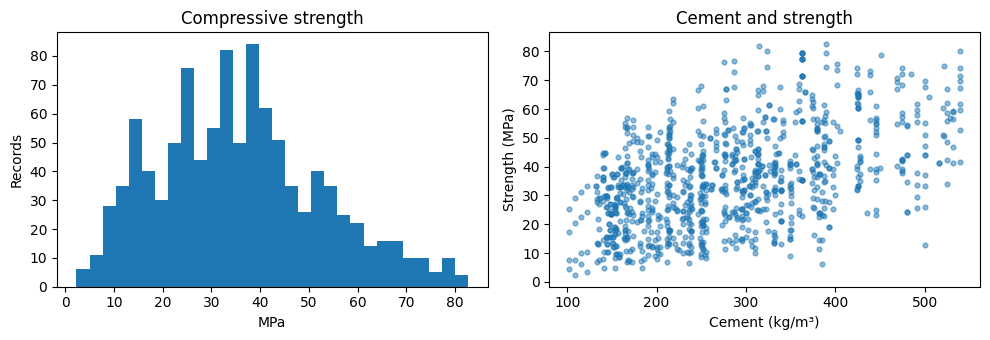

Train / validation / test: 619 209 202
Shared recipe groups between train and validation: 0
Shared recipe groups between development and test: 0
Mean baseline on validation: {'MAE': 14.506, 'RMSE': np.float64(17.595), 'R2': -0.002}


In [2]:
concrete=pd.read_csv('data/Concrete_Data.csv');concrete.columns=concrete.columns.str.strip()
X=concrete.iloc[:,:-1];y=concrete.iloc[:,-1]
print('Shape:',concrete.shape,'| Missing cells:',int(concrete.isna().sum().sum()))
print('Exact duplicate rows:',int(concrete.duplicated().sum()),'| Repeated predictor rows:',int(X.duplicated().sum()))
print('Descriptive statistics:');print(concrete.describe().round(2).to_string())
print('Correlation with strength:');print(concrete.corr(numeric_only=True).iloc[:-1,-1].sort_values(ascending=False).round(3).to_string())
fig,ax=plt.subplots(1,2,figsize=(10,3.5));ax[0].hist(y,bins=30);ax[0].set(title='Compressive strength',xlabel='MPa',ylabel='Records');ax[1].scatter(X.iloc[:,0],y,s=12,alpha=.5);ax[1].set(title='Cement and strength',xlabel='Cement (kg/m³)',ylabel='Strength (MPa)');plt.tight_layout();plt.show()
groups=pd.util.hash_pandas_object(X,index=False).to_numpy()
outer=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
idev,ite=next(outer.split(X,y,groups));Xdev,Xtest=X.iloc[idev],X.iloc[ite];ydev,ytest=y.iloc[idev],y.iloc[ite]
inner=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,iva=next(inner.split(Xdev,ydev,groups[idev]));Xtr,Xva=Xdev.iloc[itr],Xdev.iloc[iva];ytr,yva=ydev.iloc[itr],ydev.iloc[iva]
print('Train / validation / test:',len(Xtr),len(Xva),len(Xtest))
print('Shared recipe groups between train and validation:',len(set(groups[idev][itr])&set(groups[idev][iva])))
print('Shared recipe groups between development and test:',len(set(groups[idev])&set(groups[ite])))
def reg_metrics(ytrue,p):return {'MAE':mean_absolute_error(ytrue,p),'RMSE':np.sqrt(mean_squared_error(ytrue,p)),'R2':r2_score(ytrue,p)}
mean_model=DummyRegressor(strategy='mean').fit(Xtr,ytr)
print('Mean baseline on validation:',{k:round(v,3) for k,v in reg_metrics(yva,mean_model.predict(Xva)).items()})

## Question 2. Compare linear and nonlinear approaches, inspect residuals, and identify weak predictions

I compare **Ridge regression** (linear, scaled predictors), **random forest regression** (nonlinear ensemble), and **histogram gradient boosting** (nonlinear additive tree ensemble). Hyperparameters are fixed before evaluating the holdout. I rank approaches on validation MAE and use RMSE to highlight large mistakes. I examine residuals as observed minus predicted strength, including error by curing-age group and by observed-strength quartile. I report group sample sizes so small subgroups are not overinterpreted.

Validation comparison (lower MAE and RMSE are better):
                 Model    MAE   RMSE     R2
     Gradient boosting  3.207  4.685  0.929
         Random forest  3.819  5.303  0.909
      Ridge regression  9.034 11.140  0.598
Training mean baseline 14.506 17.595 -0.002
Selected nonlinear/linear model based on validation MAE: Gradient boosting


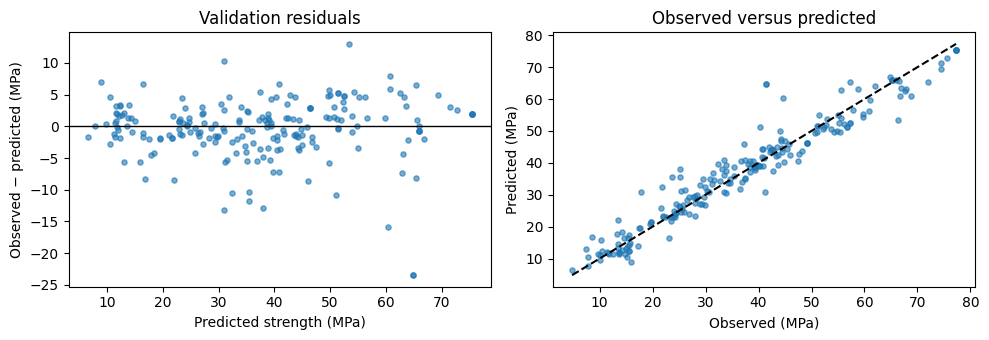

Validation error by curing age:
             n   MAE
age_band            
1–7 days    54  3.25
8–28 days   96  3.41
29–90 days  31  2.79
>90 days    28  2.89
Validation error by observed strength quartile:
                    n   MAE
strength_quartile          
(4.781, 24.001]    53  2.91
(24.001, 36.439]   52  2.82
(36.439, 49.201]   54  3.75
(49.201, 77.297]   50  3.34
Five largest validation errors:
 observed  predicted  absolute_error  age  age_band strength_quartile
    41.37      64.84           23.48   28 8–28 days  (36.439, 49.201]
    41.37      64.84           23.48   28 8–28 days  (36.439, 49.201]
    44.52      60.34           15.82   28 8–28 days  (36.439, 49.201]
    17.84      30.99           13.15   14 8–28 days   (4.781, 24.001]
    66.42      53.43           13.00  100  >90 days  (49.201, 77.297]


FINAL HELD-OUT TEST: Gradient boosting {'MAE': 3.313, 'RMSE': np.float64(4.894), 'R2': 0.904}
TEST mean baseline: {'MAE': 12.747, 'RMSE': np.float64(15.868), 'R2': -0.011}


In [3]:
reg_models={'Ridge regression':Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=10))]),'Random forest':RandomForestRegressor(n_estimators=220,min_samples_leaf=2,n_jobs=-1,random_state=SEED),'Gradient boosting':HistGradientBoostingRegressor(max_iter=220,max_leaf_nodes=15,l2_regularization=2,random_state=SEED)}
reg_rows=[{'Model':'Training mean baseline',**reg_metrics(yva,mean_model.predict(Xva))}];reg_fit={}
for name,model in reg_models.items():
 model.fit(Xtr,ytr);reg_fit[name]=model;reg_rows.append({'Model':name,**reg_metrics(yva,model.predict(Xva))})
reg_table=pd.DataFrame(reg_rows).sort_values('MAE').reset_index(drop=True)
print('Validation comparison (lower MAE and RMSE are better):');print(reg_table.round(3).to_string(index=False))
winner=reg_table.loc[reg_table.Model!='Training mean baseline'].iloc[0].Model
selected=reg_fit[winner];pv=selected.predict(Xva);res=yva.to_numpy()-pv
print('Selected nonlinear/linear model based on validation MAE:',winner)
fig,ax=plt.subplots(1,2,figsize=(10,3.5));ax[0].scatter(pv,res,s=14,alpha=.6);ax[0].axhline(0,color='black',linewidth=1);ax[0].set(xlabel='Predicted strength (MPa)',ylabel='Observed − predicted (MPa)',title='Validation residuals');ax[1].scatter(yva,pv,s=14,alpha=.6);lims=[min(yva.min(),pv.min()),max(yva.max(),pv.max())];ax[1].plot(lims,lims,color='black',linestyle='--');ax[1].set(xlabel='Observed (MPa)',ylabel='Predicted (MPa)',title='Observed versus predicted');plt.tight_layout();plt.show()
diag=pd.DataFrame({'observed':yva.to_numpy(),'predicted':pv,'absolute_error':np.abs(res),'age':Xva.iloc[:,-1].to_numpy()})
diag['age_band']=pd.cut(diag.age,bins=[0,7,28,90,np.inf],labels=['1–7 days','8–28 days','29–90 days','>90 days'],include_lowest=True)
diag['strength_quartile']=pd.qcut(diag.observed,4,duplicates='drop')
print('Validation error by curing age:');print(diag.groupby('age_band',observed=True).agg(n=('absolute_error','size'),MAE=('absolute_error','mean')).round(2).to_string())
print('Validation error by observed strength quartile:');print(diag.groupby('strength_quartile',observed=True).agg(n=('absolute_error','size'),MAE=('absolute_error','mean')).round(2).to_string())
print('Five largest validation errors:');print(diag.nlargest(5,'absolute_error').round(2).to_string(index=False))
pt=selected.predict(Xtest)
print('FINAL HELD-OUT TEST:',winner,{k:round(v,3) for k,v in reg_metrics(ytest,pt).items()})
print('TEST mean baseline:',{k:round(v,3) for k,v in reg_metrics(ytest,mean_model.predict(Xtest)).items()})

### Diagnostic interpretation and robustness

The validation residual plot reveals whether errors increase with predicted strength or follow a systematic pattern. The age-band and strength-quartile tables identify the weakest prediction regions **empirically**, rather than assuming that high-strength or early-age mixtures must be the hardest. Any subgroup with few observations requires cautious interpretation. The grouped split tests generalisation to unseen *input recipes*, but it does not establish performance on new plants, raw-material sources, laboratories, or curing regimes. The test results are reported only after validation-based model selection.

## Question 3. Does the cement–strength association prove the effect of changing cement content in practice?

**No.** The observed association is predictive, not necessarily causal. Cement quantity is jointly determined with water, supplementary cementitious materials, aggregates, admixtures, curing age, and design constraints. In particular, the water-to-cement ratio and interactions among ingredients may affect strength. Increasing cement while keeping the rest of a recipe fixed can also change workability and total mixture proportions, producing conditions unlike those in the historical dataset. Consequently, a model prediction under a hypothetical cement change may extrapolate beyond the combinations actually observed.

To estimate the causal effect of changing cement, I would specify a feasible intervention, hold other mixture-design factors controlled where physically appropriate, prepare replicated batches across cement levels, standardise curing and testing, and compare strength with uncertainty intervals. A designed experiment or credible causal identification strategy is required before claiming that increasing cement will cause a specific strength change. The present model is useful for screening plausible recipes, not replacing laboratory validation or structural safety standards.

**References:** Yeh, I.-C. (1998). Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research, 28*(12), 1797–1808. https://doi.org/10.1016/S0008-8846(98)00165-3; Pearl, J., & Mackenzie, D. (2018). *The Book of Why*. Basic Books.